# Mock Lab 2 — House Price (Regression + KNN Regressor + PCA)
**เวลา:** 75 นาที · **seed = 1992** · hold-out 80/20 (`random_state=1992`) · CV = KFold 5 folds (shuffle, seed 1992) บน training set
ข้อมูล `data/housing.csv` (503 หลัง, target = `medv` ราคาบ้านเป็นพันดอลลาร์) · `data/new_houses.csv` = บ้านใหม่ 3 หลังให้ทำนาย

## ตั้งต้น

In [1]:
import warnings; warnings.filterwarnings("ignore", category=UserWarning)   # ซ่อน warning precision=0 ของ baseline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (precision_score, recall_score, f1_score, confusion_matrix,
                             mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score,
                             silhouette_score, davies_bouldin_score)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from mlxtend.frequent_patterns import apriori, association_rules
SEED = 1992

## Part A · EDA (20 คะแนน)

**A1.** สรุปสถิติของ `medv` + histogram · การกระจายเป็นอย่างไร มีอะไรผิดปกติ

(503, 14)
count    503.00
mean      22.55
std        9.22
min        5.00
25%       16.90
50%       21.20
75%       25.00
max       50.00
Name: medv, dtype: float64
skew = 1.101 | จำนวนบ้าน medv = 50: 16


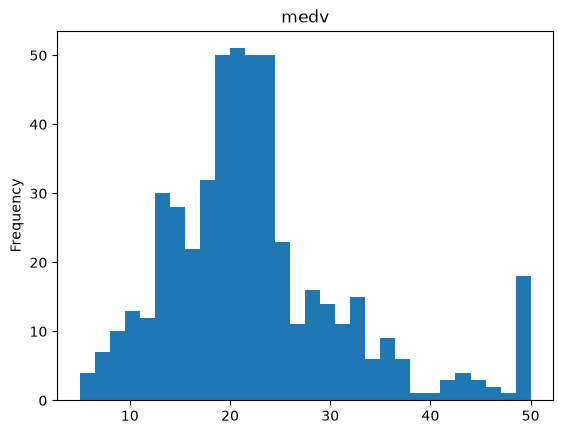

In [2]:
h = pd.read_csv("data/housing.csv")
print(h.shape)
print(h["medv"].describe().round(2))
print("skew =", round(h["medv"].skew(), 3), "| จำนวนบ้าน medv = 50:", (h["medv"] == 50).sum())
h["medv"].plot.hist(bins=30, title="medv"); plt.show()

> **✅ เฉลย / การตีความ**
>
> mean 22.55 > median 21.2 · **skew = 1.10 (เบ้ขวา)** · มีบ้าน **medv = 50.0 ถึง 16 หลัง** กองที่ค่าสูงสุดพอดี → น่าจะถูก **ตัดเพดาน (censored at 50)** ไม่ใช่ราคาจริง → ควรเขียนกำกับว่าโมเดลจะทายบ้านแพงต่ำกว่าจริง

**A2.** heatmap correlation · ตัวแปรใด 3 ตัวที่สัมพันธ์กับ `medv` มากที่สุด (|r|) · คู่ predictor ใดสัมพันธ์กันเองสูงสุด และเป็นปัญหาอย่างไร

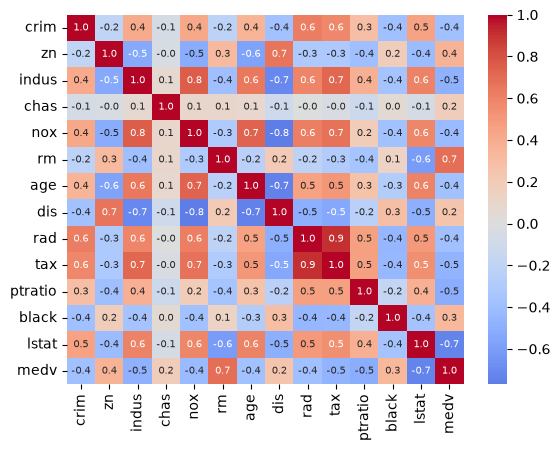

lstat     -0.738
rm         0.696
ptratio   -0.508
Name: medv, dtype: float64
rad    tax    0.910
nox    dis    0.769
indus  nox    0.765
dtype: float64


In [3]:
corr = h.corr()
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 7}); plt.show()
r = corr["medv"].drop("medv")
print(r.reindex(r.abs().sort_values(ascending=False).index).head(3).round(3))
pred_corr = h.drop(columns="medv").corr().abs()
pairs = pred_corr.where(np.triu(np.ones(pred_corr.shape, bool), k=1)).stack().sort_values(ascending=False)
print(pairs.head(3).round(3))

> **✅ เฉลย / การตีความ**
>
> top 3: **lstat (r = −0.738)**, **rm (+0.696)**, **ptratio (−0.508)** → ชุมชนรายได้ต่ำมาก ราคาต่ำ · ห้องมาก ราคาสูง · ครูน้อยต่อนักเรียน ราคาต่ำ
> คู่ predictor: **rad–tax r = 0.91**, nox–dis 0.77, indus–nox 0.77 → **multicollinearity**: coefficient ของ rad/tax ใน linear regression จะไม่เสถียร ตีความยาก (เครื่องหมายอาจกลับ) · แนวทาง: เก็บตัวเดียว / รวม / ใช้ regularization

## Part B · Linear Regression (30 คะแนน)

**B1.** split 80/20 · เทียบ **mean baseline**, Linear Regression ทุกตัวแปร, Linear Regression 2 ตัว (lstat, rm) ด้วย MAE / MSE / RMSE / R² บน test

In [4]:
X, y = h.drop(columns="medv"), h["medv"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

def test_row(name, model, cols=None):
    cols = cols or list(X.columns)
    p = model.fit(X_train[cols], y_train).predict(X_test[cols])
    return {"model": name, "MAE": mean_absolute_error(y_test, p), "MSE": mean_squared_error(y_test, p),
            "RMSE": root_mean_squared_error(y_test, p), "R2": r2_score(y_test, p)}

pd.DataFrame([test_row("Mean baseline", DummyRegressor(strategy="mean")),
              test_row("LinReg (13 features)", LinearRegression()),
              test_row("LinReg (lstat, rm)", LinearRegression(), ["lstat", "rm"])]).round(3)

,model,MAE,MSE,RMSE,R2
0,Mean baseline,7.019,106.169,10.304,-0.029
1,LinReg (13 features),3.889,36.152,6.013,0.649
2,"LinReg (lstat, rm)",4.562,44.060,6.638,0.573


> **✅ เฉลย / การตีความ**
>
> | model | MAE | MSE | RMSE | R² |
> |---|---|---|---|---|
> | Mean baseline | 7.019 | 106.17 | 10.304 | −0.029 |
> | LinReg 13 ตัว | **3.889** | **36.15** | **6.013** | **0.649** |
> | LinReg 2 ตัว | 4.562 | 44.06 | 6.638 | 0.573 |
> ทั้งสองดีกว่า baseline มาก (RMSE ลด ~40%) · 13 ตัวดีกว่า 2 ตัว (R² +0.076) แต่ 2 ตัวง่ายกว่ามาก → เลือกตามเป้าหมาย (ทำนาย vs อธิบาย)

**B2.** เขียนสมการของโมเดล 2 ตัวแปร และตีความ coefficient · ในโมเดล 13 ตัว coefficient ของ `nox` = −16.4 แปลว่าอะไร และทำไมไม่ควรสรุปว่า nox สำคัญที่สุด

In [5]:
lin2 = LinearRegression().fit(X_train[["lstat", "rm"]], y_train)
print(f"medv = {lin2.intercept_:.3f} + ({lin2.coef_[0]:.4f})·lstat + ({lin2.coef_[1]:.4f})·rm")
lin13 = LinearRegression().fit(X_train, y_train)
print(pd.Series(lin13.coef_, index=X.columns).round(4))
print(X[["nox", "rm", "tax"]].std().round(3))

medv = -1.616 + (-0.6101)·lstat + (5.0500)·rm
crim       -0.1011
zn          0.0463
indus       0.0559
chas        0.9995
nox       -16.3842
rm          4.2025
age        -0.0024
dis        -1.2310
rad         0.2920
tax        -0.0143
ptratio    -0.9754
black       0.0095
lstat      -0.4223
dtype: float64
nox      0.116
rm       0.704
tax    168.584
dtype: float64


> **✅ เฉลย / การตีความ**
>
> **medv = −1.616 − 0.610·lstat + 5.050·rm** → lstat เพิ่ม 1 จุด % ราคาลด 0.61 พันดอลลาร์ (rm คงที่) · ห้องเพิ่ม 1 ห้อง ราคาเพิ่ม 5.05 พันดอลลาร์ (lstat คงที่)
> nox = −16.4 → nox เพิ่ม **1 หน่วย** ราคาลด 16.4 พันดอลลาร์ (ตัวอื่นคงที่) — แต่ nox มี SD แค่ **0.116** (1 หน่วยกว้างกว่าช่วงข้อมูลทั้งหมด) → coefficient ใหญ่เพราะ **หน่วยเล็ก** · เทียบความสำคัญต้องใช้ **standardized coefficient** (หรือ coef × SD) · และ nox สัมพันธ์สูงกับ dis/indus (multicollinearity)

## Part C · KNN Regressor (25 คะแนน)

**C1.** เทียบ KNN regressor (k = 5) **ไม่ scale vs StandardScaler** และ Linear Regression ด้วย 5-fold CV บน training set (RMSE, R²) · **C2.** Optimize k = 1–20 × weights ∈ {uniform, distance} แล้วประเมินตัวที่ดีที่สุดบน test

In [6]:
kcv = KFold(n_splits=5, shuffle=True, random_state=SEED)
cands = {"KNN raw k=5": KNeighborsRegressor(n_neighbors=5),
         "KNN scaled k=5": Pipeline([("sc", StandardScaler()), ("knn", KNeighborsRegressor(n_neighbors=5))]),
         "LinReg": LinearRegression()}
rows = []
for name, m in cands.items():
    r = cross_validate(m, X_train, y_train, cv=kcv, scoring=["neg_root_mean_squared_error", "r2"])
    rows.append({"model": name, "CV RMSE": -r["test_neg_root_mean_squared_error"].mean(), "CV R2": r["test_r2"].mean()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

grid = GridSearchCV(Pipeline([("sc", StandardScaler()), ("knn", KNeighborsRegressor())]),
                    {"knn__n_neighbors": range(1, 21), "knn__weights": ["uniform", "distance"]},
                    cv=kcv, scoring="neg_root_mean_squared_error").fit(X_train, y_train)
print(grid.best_params_, "CV RMSE =", round(-grid.best_score_, 3))
pd.DataFrame([test_row("KNN tuned (test)", grid.best_estimator_)]).round(3)

         model  CV RMSE  CV R2
   KNN raw k=5    6.318  0.483
KNN scaled k=5    4.436  0.749
        LinReg    4.678  0.715


{'knn__n_neighbors': 6, 'knn__weights': 'distance'} CV RMSE = 4.219


,model,MAE,MSE,RMSE,R2
0,KNN tuned (test),2.843,25.083,5.008,0.757


> **✅ เฉลย / การตีความ**
>
> | model | CV RMSE | CV R² |
> |---|---|---|
> | KNN raw k=5 | 6.318 | 0.483 |
> | **KNN scaled k=5** | **4.436** | **0.749** |
> | LinReg | 4.678 | 0.715 |
> **scaling ลด RMSE 30%** (6.32 → 4.44) เพราะ tax/black (หลักร้อย) ครองระยะทาง · KNN scaled ชนะ LinReg เล็กน้อย → ความสัมพันธ์มีส่วนที่ไม่เป็นเชิงเส้น
> best: **k = 6, weights = distance** (CV RMSE 4.219) → test **RMSE 5.008, R² 0.757** ดีกว่า LinReg บน test (6.013 / 0.649)

## Part D · PCA (25 คะแนน)

**D1.** standardize 13 feature แล้วทำ PCA: ตาราง explained variance + cumulative · ต้องใช้กี่ component ถึง 80% · ถ้าใช้เกณฑ์ eigenvalue > 1 ได้กี่ตัว · **D2.** loading สูงสุดของ PC1 (4 ตัว) และ PC2 (3 ตัว) ตีความ · **D3.** scatter PC1 × PC2 ระบายสีตาม medv 3 ช่วง (equal frequency: Low/Mid/High)

     explained  cumulative  eigenvalue
PC1     0.4722      0.4722      6.1503
PC2     0.1102      0.5824      1.4353
PC3     0.0954      0.6778      1.2430
PC4     0.0659      0.7437      0.8590
PC5     0.0641      0.8078      0.8346
PC6     0.0506      0.8584      0.6587
PC for 80%: 5 | eigenvalue > 1: 3
         PC1    PC2
indus  0.346  0.115
nox    0.343  0.218
tax    0.339 -0.238
dis   -0.321 -0.348
        PC1    PC2
chas  0.005  0.455
dis  -0.321 -0.348
zn   -0.256 -0.326


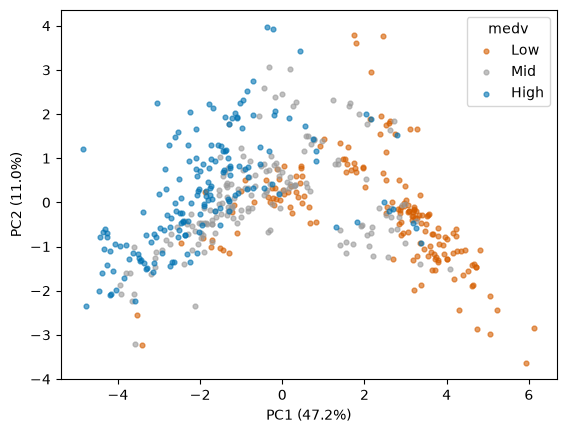

       PC1   PC2
Low   2.24 -0.25
Mid  -0.44  0.05
High -1.84  0.21


In [7]:
Z = StandardScaler().fit_transform(X)        # PCA เพื่ออธิบาย/visualize ทำกับข้อมูลทั้งชุดได้ (ไม่ได้ใช้วัดผลโมเดล)
pca = PCA().fit(Z)
evr = pd.DataFrame({"explained": pca.explained_variance_ratio_, "cumulative": pca.explained_variance_ratio_.cumsum(),
                    "eigenvalue": pca.explained_variance_}, index=[f"PC{i+1}" for i in range(13)]).round(4)
print(evr.head(6))
print("PC for 80%:", int((evr["cumulative"] < 0.8).sum() + 1), "| eigenvalue > 1:", int((evr["eigenvalue"] > 1).sum()))
load = pd.DataFrame(pca.components_[:2].T, index=X.columns, columns=["PC1", "PC2"]).round(3)
print(load.reindex(load["PC1"].abs().sort_values(ascending=False).index).head(4))
print(load.reindex(load["PC2"].abs().sort_values(ascending=False).index).head(3))
band = pd.qcut(y, 3, labels=["Low", "Mid", "High"])
P = pca.transform(Z)[:, :2]
for b, c in zip(["Low", "Mid", "High"], ["#D55E00", "#999999", "#0072B2"]):
    m = (band == b).to_numpy()
    plt.scatter(P[m, 0], P[m, 1], s=12, alpha=0.6, color=c, label=b)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})"); plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.legend(title="medv"); plt.show()
print(pd.DataFrame(P, columns=["PC1", "PC2"]).groupby(band.values, observed=True).mean().round(2))

> **✅ เฉลย / การตีความ**
>
> PC1 **47.2%**, PC2 11.0%, PC3 9.5% → สะสม 47.2 → 58.2 → 67.8 → 74.4 → **80.8%** → ต้องใช้ **5 components** ถึง 80% · eigenvalue > 1 (Kaiser) ได้ **3 ตัว**
> PC1 loading: indus +0.35, nox +0.34, tax +0.34, dis −0.32 → **"ความเป็นเขตอุตสาหกรรม/เมืองชั้นใน"** (โรงงาน มลพิษ ภาษีสูง ใกล้ศูนย์กลาง) · PC2: chas +0.46, dis −0.35, zn −0.33 → ติดแม่น้ำ/ใกล้เมือง
> scatter: ค่าเฉลี่ย PC1 ของบ้าน Low = **+2.24**, Mid −0.44, High **−1.84** → **บ้านราคาต่ำอยู่ฝั่ง PC1 สูง** (เขตอุตสาหกรรม) แยกตามแกน PC1 ได้ชัด ส่วน PC2 แยกไม่ค่อยได้ · ⚠️ 2 PC เก็บได้แค่ 58% ของความแปรปรวน

**E.** ทำนายราคา `new_houses.csv` ด้วย Linear Regression (13 ตัว) และ KNN ที่ดีที่สุด · แล้วเปิด `new_houses_answer.csv` เทียบ

In [8]:
new = pd.read_csv("data/new_houses.csv")
truth = pd.read_csv("data/new_houses_answer.csv")["medv"]
pd.DataFrame({"LinReg": lin13.predict(new).round(2),
              "KNN tuned": grid.best_estimator_.predict(new).round(2), "actual": truth})

,LinReg,KNN tuned,actual
0,20.33,20.91,21.8
1,20.43,19.70,19.3
2,19.03,20.06,19.9


> **✅ เฉลย / การตีความ**
>
> | | LinReg | KNN tuned | actual |
> |---|---|---|---|
> | บ้าน 1 | 20.33 | 20.91 | 21.8 |
> | บ้าน 2 | 20.43 | 19.70 | 19.3 |
> | บ้าน 3 | 19.03 | 20.06 | 19.9 |
> KNN ใกล้ค่าจริงกว่าใน 3 หลังนี้ (|error| เฉลี่ย **0.48** vs **1.16**) สอดคล้องกับผล test · **เลือก KNN (k = 6, distance, scaled)** เพื่อทำนาย · ถ้าต้องอธิบายปัจจัยราคา ใช้ LinReg ประกอบ